# 05 · A booking-time distance estimate, and a closer look at the fares
**Added after the final evaluation (2026-11-15).** Status: `[x]`

Two additions, neither of which changes the frozen model or touches July *predictions*:
- **Part A:** a simple "routing engine" so the predictor no longer needs the odometer distance: straight-line distance between zone centroids × a detour factor learned on **May**, evaluated on **June**. July is locked and is **not** used to evaluate it.
- **Part B:** descriptive statistics of the fares (quartiles, means, medians), the most expensive and cheapest trips and places, and why. Mostly May; §B2 compares the three months' fare *distributions* only (no model involved).

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.config import TARGET, FINAL_FEATURE_SET, FINAL_MODEL, FINAL_PARAMS, BUFFER_Q, ZONES_FILE, AIRPORT_ZONES
from src.clean import build_datasets
from src.features import add_features
from src.models import make_pipeline, make_model
from src.routing import StraightLineRouter
from src.evaluate import metrics, fit_quote_rule, apply_quote_rule, quote_report, slice_table, save_results
from src.eda import with_trip_measures, describe_table, quartiles_by, ranked_groups, histogram, describe
import json
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 160)

D = build_datasets()
train, val = D["train"], D["val"]
ytr, yva = train[TARGET], val[TARGET]
zones = pd.read_csv(ZONES_FILE).set_index("LocationID")
zname = lambda i: f"{zones.Zone.get(i, '?')} ({zones.Borough.get(i, '?')})"
gate3 = json.loads(open("../results/gate3_freeze.json").read())

## Part A · Straight-line distance as the planned route

### A1 · Fit on May
For trips between two different zones, the estimate is `k × straight line`, where `k` is the median of (trip distance / centroid-to-centroid straight line) over May trips **in the same straight-line length band**. One global `k` under-estimated long trips (bridges, highways) by about 2.9 mi at 10–20 mi on June, so the factor depends on length. For trips inside one zone the straight line is 0, so we use that zone's median May distance (zones with ≥ 20 such trips) or the overall same-zone median.

In [2]:
router = StraightLineRouter().fit(train)
print(f"detour factor k = {router.k_:.3f}  (fitted on {router.n_fit_:,} May trips between different zones)")
print("quantiles of actual / straight-line:", {q: round(v, 3) for q, v in router.ratio_quantiles_.items()})
display(pd.DataFrame({"straight-line band (mi)": [f"{a}-{b}" for a, b in zip(router.BAND_EDGES, list(router.BAND_EDGES[1:]) + ["inf"])],
                      "k": np.round(router.k_band_, 3), "May trips": router.n_band_}))
print(f"same-zone: {len(router.same_zone_)} zones with their own median; default {router.same_zone_default_:.2f} mi")

detour factor k = 1.238  (fitted on 127,534 May trips between different zones)
quantiles of actual / straight-line: {0.1: 0.824, 0.25: 1.015, 0.5: 1.238, 0.75: 1.508, 0.9: 1.854}


,straight-line band (mi),k,May trips
0,0.0-0.5,1.791,7891
1,0.5-1.0,1.223,35205
2,1.0-2.0,1.167,45185
3,2.0-3.0,1.181,17005
4,3.0-5.0,1.279,12615
5,5.0-8.0,1.461,7079
6,8.0-12.0,1.394,2296
7,12.0-inf,1.349,258


same-zone: 41 zones with their own median; default 0.56 mi


### A2 · How close is the estimate to the real (odometer) distance? (June)

{'n': 133459, 'mae_mi': np.float64(0.532), 'median_abs_pct': np.float64(0.19), 'bias_mi': np.float64(0.106)}


,n,mae_mi,median_abs_pct,bias_mi
band,,,,
0-1,36033,0.271,0.297,-0.200
1-2,46274,0.312,0.178,0.018
2-5,34785,0.565,0.155,0.176
5-10,11375,1.375,0.160,0.584
10-20,4825,2.214,0.163,1.451
20+,167,5.018,0.226,4.677


[Text(0.5, 0, 'actual (odometer) miles'),
 Text(0, 0.5, 'estimated miles'),
 Text(0.5, 1.0, 'June: estimated vs actual distance')]

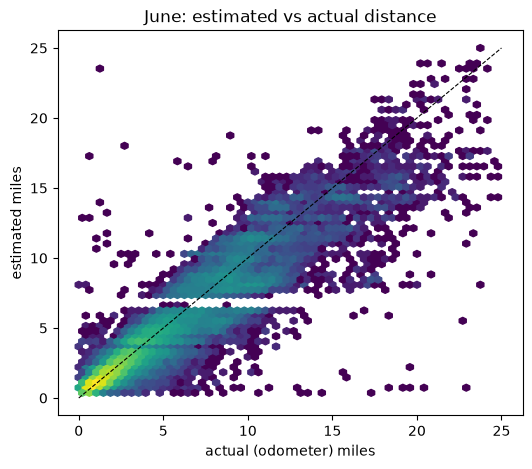

In [3]:
est_va = router.predict(val.PULocationID, val.DOLocationID)
act = val.trip_distance.to_numpy()
fv = add_features(val)
err = pd.DataFrame({"band": fv.dist_band.astype(str).to_numpy(), "abs": np.abs(est_va - act), "pct": np.abs(est_va - act) / act, "signed": act - est_va})
dist_err = {"all": dict(n=len(err), mae_mi=err["abs"].mean(), median_abs_pct=err.pct.median(), bias_mi=err.signed.mean())}
by_band = err.groupby("band").agg(n=("abs", "size"), mae_mi=("abs", "mean"), median_abs_pct=("pct", "median"), bias_mi=("signed", "mean")).loc[["0-1", "1-2", "2-5", "5-10", "10-20", "20+"]]
print({k: round(v, 3) for k, v in dist_err["all"].items()})
display(by_band.round(3))
fig, ax = plt.subplots(figsize=(6, 5)); ax.hexbin(act, est_va, gridsize=60, bins="log", mincnt=1, extent=(0, 25, 0, 25))
ax.plot([0, 25], [0, 25], "k--", lw=.8); ax.set(xlabel="actual (odometer) miles", ylabel="estimated miles", title="June: estimated vs actual distance")

**Read it.** The estimate is off by **0.53 mi on average** (median error 19%), with almost no overall bias (+0.11 mi). Errors grow with length: under 1 mi it slightly *over*-estimates (the 0.56 mi same-zone default and the short-hop factor 1.79), while 10–20 mi trips are still *under*-estimated by 1.45 mi on average. The straight line can't know which bridge or highway a driver takes. For comparison, a single global factor (k = 1.24) had a 0.57 mi average error and under-estimated 10–20 mi trips by 2.85 mi.

### A3 · What does the estimate cost the model? (June)
Three ways to price June trips, all trained on May:
1. the frozen model with the **odometer** distance (the official setting, as evaluated on July),
2. the **same frozen model** fed the **estimated** distance (what the website does),
3. the same model specification **retrained on May with estimated distances** (an experiment; not adopted, so the frozen model stays the final model).

In [4]:
frozen = make_pipeline(make_model(FINAL_MODEL, **FINAL_PARAMS), FINAL_FEATURE_SET).fit(train, ytr)
val_est = router.apply(val)
retrained = make_pipeline(make_model(FINAL_MODEL, **FINAL_PARAMS), FINAL_FEATURE_SET).fit(router.apply(train), ytr)
preds = {"frozen model, odometer distance": frozen.predict(val),
         "frozen model, estimated distance": frozen.predict(val_est),
         "retrained on estimated distance": retrained.predict(val_est)}
# experiment, not adopted: May median distance of the same zone pair (>= 10 trips), straight line otherwise
pm = train.groupby(["PULocationID", "DOLocationID"]).trip_distance.agg(["median", "size"])
look = pm[pm["size"] >= 10]["median"].to_dict()
val_pair = val_est.copy()
val_pair["trip_distance"] = [look.get((a, b), e) for a, b, e in zip(val.PULocationID, val.DOLocationID, val_est.trip_distance)]
preds["frozen model, zone-pair history distance (experiment)"] = frozen.predict(val_pair)
band_act = fv.dist_band.astype(str).to_numpy()
band_est = add_features(val_est).dist_band.astype(str).to_numpy()
rule = gate3["quote_rule"]
rows = {}
for k, p in preds.items():
    b = band_act if "odometer" in k else add_features(val_pair).dist_band.astype(str).to_numpy() if "pair" in k else band_est
    rows[k] = {**metrics(yva, p), "coverage_frozen_rule": quote_report(yva, apply_quote_rule(rule, p, b))["coverage"]}
cost = pd.DataFrame(rows).T.drop(columns="n"); cost.round(3)

,mae,rmse,bias,coverage_frozen_rule
"frozen model, odometer distance",2.082,3.234,0.421,0.900
"frozen model, estimated distance",3.255,4.837,0.661,0.822
retrained on estimated distance,2.939,4.401,0.441,0.852
"frozen model, zone-pair history distance (experiment)",3.037,4.576,0.660,0.833


**Read it.** Not knowing the real distance is expensive. Fed the straight-line estimate, the frozen model's June MAE rises from **\$2.08 to \$3.26** (+57%), and the frozen quote rule would cover only **82%** of trips instead of 90%. Retraining on estimated distances recovers part of it (\$2.94), because the model then learns how much each zone pair really costs instead of trusting a distance it no longer gets. Using the May median distance of the same zone pair (where it has ≥ 10 trips) instead of the straight line gives \$3.04 with the frozen model. **Not adopted:** the frozen, July-evaluated model stays the final model; the website uses it with the straight-line estimate and the re-calibrated quote rule below. If a user types a real routing distance, the website uses the original buffers.

### A4 · A quote rule for estimated distances (June)
With an estimated distance the errors are larger, so the frozen buffers (fitted to odometer-distance errors) would under-cover. We fit the **same kind of rule** (90th percentile of June residuals per distance band, with the band taken from the *estimated* distance) to the frozen model's June errors on estimated distances. The website uses this rule whenever the distance comes from the estimator. Reported coverage is **cross-fitted** (odd days → even days and back), so it is not in-sample. It has not been, and cannot be, checked on July.

In [5]:
p_est = preds["frozen model, estimated distance"]; y = yva.to_numpy(); day = val.tpep_pickup_datetime.dt.day.to_numpy()
q = np.empty(len(y))
for h in (0, 1):
    fit, ev = day % 2 == h, day % 2 != h
    q[ev] = apply_quote_rule(fit_quote_rule("by_dist_band", y[fit], p_est[fit], BUFFER_Q, slices=band_est[fit]), p_est[ev], band_est[ev])
rule_est = fit_quote_rule("by_dist_band", y, p_est, BUFFER_Q, slices=band_est)
print("estimated-distance buffers:", {k: round(v, 2) for k, v in rule_est["b"].items()}, "| default", round(rule_est["default"], 2))
print("frozen (odometer) buffers: ", {k: round(v, 2) for k, v in rule["b"].items()})
xfit = quote_report(y, q); print("cross-fitted June coverage:", {k: round(v, 3) for k, v in xfit.items()})
vs = val_est.assign(hour_band=fv.hour_band.to_numpy(), dist_band=band_est, airport_trip=fv.airport_trip.to_numpy())
est_slices = {by: slice_table(vs, y, p_est, by, quote=q).round(4) for by in ["dist_band", "hour_band", "airport_trip"]}
for by, t in est_slices.items(): display(t)

estimated-distance buffers: {'0-1': 4.45, '1-2': 4.81, '10-20': 12.85, '2-5': 6.55, '20+': 6.04, '5-10': 11.02} | default 6.04
frozen (odometer) buffers:  {'0-1': 2.79, '1-2': 3.58, '10-20': 6.99, '2-5': 4.62, '20+': 3.93, '5-10': 5.36}
cross-fitted June coverage: {'n': 133459, 'coverage': 0.9, 'mean_overquote': 5.673, 'mean_cushion': 5.27, 'mean_shortfall_when_under': 4.02}


,n,mae,rmse,bias,coverage
dist_band,,,,,
0-1,32106,2.2417,3.7272,0.9070,0.8995
1-2,50873,2.7493,3.8886,0.3571,0.8998
10-20,4199,7.1863,9.4737,0.5695,0.8978
2-5,35773,3.7191,5.0440,0.3810,0.8998
20+,53,7.3859,12.8892,-3.2445,0.8868
5-10,10455,5.6361,7.6478,2.3954,0.8996


,n,mae,rmse,bias,coverage
hour_band,,,,,
am 6-9,15180,3.0165,4.5801,0.5638,0.9197
eve 20-23,28104,2.9333,4.4554,0.7273,0.9200
midday 10-15,44416,3.5414,5.1766,0.5967,0.8836
night 0-5,9920,3.0587,4.6626,0.9486,0.9195
pm 16-19,35839,3.3066,4.8423,0.6492,0.8897


,n,mae,rmse,bias,coverage
airport_trip,,,,,
0,124314,2.9938,4.3551,0.4321,0.9046
1,9145,6.8012,9.1444,3.7684,0.8331


In [6]:
save_results({
    "k": router.k_, "k_band": router.k_band_, "band_edges": list(router.BAND_EDGES), "n_band": router.n_band_,
    "ratio_quantiles": router.ratio_quantiles_, "n_fit": router.n_fit_,
    "same_zone": router.same_zone_, "same_zone_default": router.same_zone_default_,
    "june_distance_error": {"all": dist_err["all"], "by_band": by_band.reset_index().to_dict(orient="records")},
    "june_model_cost": cost.reset_index(names="setting").to_dict(orient="records"),
    "quote_rule_estimated": rule_est, "june_crossfit_quote_estimated": xfit,
    "june_slices_estimated": {by: t.reset_index().astype({by: str}).to_dict(orient="records") for by, t in est_slices.items()},
}, "routing.json")

PosixPath('/home/blevi/school-related/Fairfare/results/routing.json')

## Part B · The fares themselves

### B1 · Summary statistics (May, cleaned: the training population)
Duration, fare per mile and speed are **after-the-trip** measures. They are used here to explain fares, never as model features.

In [7]:
may = with_trip_measures(train)
cols = ["fare_amount", "trip_distance", "duration_min", "fare_per_mile", "speed_mph"]
summary = describe_table(may, cols)
summary.round(2)

,count,mean,std,min,q1,median,q3,max
fare_amount,133342.0,16.88,11.92,3.00,9.30,13.50,20.50,96.80
trip_distance,133342.0,2.56,2.80,0.01,0.98,1.60,2.80,24.85
duration_min,133342.0,15.59,11.06,1.00,7.87,12.73,20.17,159.77
fare_per_mile,133342.0,8.87,6.81,0.75,6.26,7.90,10.09,510.00
speed_mph,133342.0,9.49,5.29,0.01,6.20,8.36,11.25,82.62


**Read it (May, n = 133 342).**
- **Fare:** mean **\$16.88**, median **\$13.50**, quartiles **\$9.30 / \$13.50 / \$20.50**, from the \$3.00 minimum to the \$96.80 cap. The mean is \$3.38 above the median: the distribution is right-skewed (many short rides, a tail of long ones).
- **Distance:** mean 2.56 mi, median 1.60 mi (Q1 0.98, Q3 2.80). Half of all trips are shorter than a mile and a half.
- **Duration:** mean 15.6 min, median 12.7 min (Q1 7.9, Q3 20.2).
- **Fare per mile:** median \$7.90 (Q1 \$6.26, Q3 \$10.09). That is far above the meter's \$3.50/mi, because of the \$3 start and the minutes billed in slow traffic.
- **Speed:** median 8.4 mph. **A quarter of trips average under 6.2 mph,** below the 12 mph at which the meter switches from distance to time billing.

### B2 · Do the months differ? (fare and distance distributions, cleaned)
Descriptive only. The model and its July score were frozen before this was computed, and nothing here feeds back into them.

In [8]:
months = {"May": D["train"], "June": D["val"], "July": D["test"]}
month_tab = pd.DataFrame({f"{m} {c}": describe(with_trip_measures(d)[c]) for m, d in months.items() for c in ["fare_amount", "trip_distance", "fare_per_mile"]}).T
month_tab.round(2)

,count,mean,std,min,q1,median,q3,max
May fare_amount,133342.0,16.88,11.92,3.00,9.30,13.50,20.50,96.80
May trip_distance,133342.0,2.56,2.80,0.01,0.98,1.60,2.80,24.85
May fare_per_mile,133342.0,8.87,6.81,0.75,6.26,7.90,10.09,510.00
June fare_amount,133459.0,16.92,12.08,3.00,9.30,12.80,20.50,96.80
June trip_distance,133459.0,2.58,2.85,0.01,0.97,1.60,2.80,24.80
June fare_per_mile,133459.0,8.92,8.67,0.88,6.21,7.82,10.05,1360.00
July fare_amount,128359.0,16.64,11.83,3.00,9.30,12.80,19.80,96.80
July trip_distance,128359.0,2.62,2.89,0.01,0.98,1.60,2.85,24.83
July fare_per_mile,128359.0,8.69,8.51,2.08,6.08,7.67,9.82,1700.00


**Read it.** The three months are very similar. Median fare: \$13.50 (May), \$12.80 (June), \$12.80 (July); mean \$16.88 / \$16.92 / \$16.64; median distance 1.60 mi in all three. July is a little cheaper per mile (median \$7.67 vs \$7.90 in May) for slightly *longer* trips (mean 2.62 mi vs 2.56). That fits faster summer traffic and the model's small over-prediction in July (bias −\$0.11). The extreme fares per mile (max \$1 360 and \$1 700) come from 0.01-mile trips that only paid the minimum fare and waiting time.

### B3 · Quartiles by trip type (May)
Box-plot numbers (10th, 25th, 50th, 75th, 90th percentile and mean) of the fare, and of fare per mile.

--- dist_band: fare


,n,mean,p10,q1,median,q3,p90
dist_band,,,,,,,
0-1,35797,8.05,5.10,6.5,7.2,9.3,11.4
1-2,46607,12.58,8.60,10.0,12.1,14.2,17.0
2-5,34931,20.16,14.20,16.3,19.1,23.3,27.5
5-10,11348,35.99,26.80,30.3,35.2,40.8,46.4
10-20,4503,55.56,43.60,47.1,53.4,62.5,70.9
20+,156,84.68,78.25,80.7,84.2,88.4,92.6


--- hour_band: fare


,n,mean,p10,q1,median,q3,p90
hour_band,,,,,,,
night 0-5,9540,16.61,6.5,8.6,12.8,20.5,31.7
am 6-9,14762,15.74,6.5,8.6,12.1,17.7,30.3
midday 10-15,44427,17.50,7.2,9.3,13.5,21.2,33.8
pm 16-19,36413,16.58,6.5,9.3,13.5,19.8,30.3
eve 20-23,28200,16.98,7.2,9.3,13.5,20.5,32.4


--- day_type: fare


,n,mean,p10,q1,median,q3,p90
day_type,,,,,,,
weekday,93715,17.10,7.2,9.3,13.5,20.5,32.4
weekend,39627,16.37,6.5,8.6,12.8,19.8,31.0


--- pickup_borough: fare


,n,mean,p10,q1,median,q3,p90
pickup_borough,,,,,,,
Bronx,48,23.69,8.39,12.45,17.7,33.28,48.22
Brooklyn,537,21.10,7.20,11.40,17.7,27.50,39.40
Manhattan,124533,15.08,6.50,8.60,12.8,18.40,26.80
Queens,8223,43.89,21.90,33.80,43.6,54.10,66.00
Staten Island,1,44.30,44.30,44.30,44.3,44.30,44.30


--- airport: fare


,n,mean,p10,q1,median,q3,p90
airport,,,,,,,
airport trip,8856,45.31,26.1,36.6,44.3,54.1,66.0
non-airport,124486,14.86,6.5,8.6,12.8,18.4,26.1


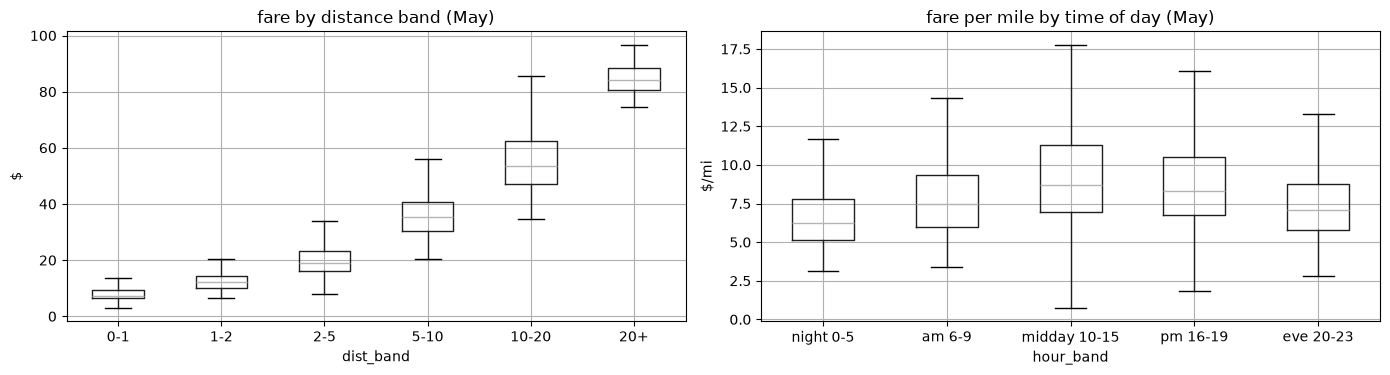

In [9]:
f = add_features(may).assign(duration_min=may.duration_min, fare_per_mile=may.fare_per_mile, speed_mph=may.speed_mph)
f["day_type"] = np.where(f.weekend == 1, "weekend", "weekday")
f["airport"] = np.where(f.airport_trip == 1, "airport trip", "non-airport")
groups = {}
for by in ["dist_band", "hour_band", "day_type", "pickup_borough", "airport"]:
    groups[by] = {"fare": quartiles_by(f, by, TARGET), "fare_per_mile": quartiles_by(f, by, "fare_per_mile")}
    print(f"--- {by}: fare"); display(groups[by]["fare"].round(2))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
f.boxplot(column=TARGET, by="dist_band", ax=ax[0], showfliers=False); ax[0].set(title="fare by distance band (May)", ylabel="$")
f.boxplot(column="fare_per_mile", by="hour_band", ax=ax[1], showfliers=False); ax[1].set(title="fare per mile by time of day (May)", ylabel="$/mi")
plt.suptitle(""); plt.tight_layout()

In [10]:
for by in ["hour_band", "pickup_borough", "airport"]:
    print(f"--- {by}: fare per mile"); display(groups[by]["fare_per_mile"].round(2))

--- hour_band: fare per mile


,n,mean,p10,q1,median,q3,p90
hour_band,,,,,,,
night 0-5,9540,6.93,4.42,5.15,6.22,7.77,9.67
am 6-9,14762,8.24,4.92,6.01,7.50,9.35,11.84
midday 10-15,44427,9.86,5.38,6.92,8.73,11.27,14.71
pm 16-19,36413,9.31,5.41,6.76,8.33,10.49,13.49
eve 20-23,28200,7.75,4.70,5.76,7.05,8.77,10.86


--- pickup_borough: fare per mile


,n,mean,p10,q1,median,q3,p90
pickup_borough,,,,,,,
Bronx,48,6.49,4.24,4.85,5.76,7.21,8.58
Brooklyn,537,7.41,4.58,5.15,6.21,8.28,10.50
Manhattan,124533,9.15,5.47,6.58,8.12,10.29,13.30
Queens,8223,4.83,3.88,4.08,4.42,4.97,5.75
Staten Island,1,5.31,5.31,5.31,5.31,5.31,5.31


--- airport: fare per mile


,n,mean,p10,q1,median,q3,p90
airport,,,,,,,
airport trip,8856,4.62,3.88,4.06,4.38,4.86,5.50
non-airport,124486,9.18,5.52,6.59,8.12,10.29,13.33


**Read it.**
- **Distance drives the fare:** the median goes from \$7.20 (under 1 mi) to \$12.10 (1–2), \$19.10 (2–5), \$35.20 (5–10), \$53.40 (10–20) and \$84.20 (20+). Within a band the spread is moderate: Q1–Q3 is \$6.50–\$9.30 under 1 mi and \$47.10–\$62.50 at 10–20 mi.
- **Time of day matters per mile, not per trip:** the median fare per mile is **\$8.73 at midday** vs **\$6.22 at night** (+40%), while the median *fare* barely moves (\$12.10–\$13.50) because night trips are longer.
- **Weekend vs weekday:** weekend trips are slightly cheaper (median \$12.80 vs \$13.50), with lighter traffic.
- **Queens pickups cost the most (median \$43.60)** but the least per mile (\$4.42/mi): they are mostly airport runs. **Airport trips:** median \$44.30 (Q1 \$36.60, Q3 \$54.10) at only \$4.38 per mile, vs \$12.80 and \$8.12 per mile for everything else.

### B4 · The most expensive and the cheapest places (May)
Ranked by the **median** fare, so a handful of odd trips cannot drive a ranking. Pickup zones need ≥ 200 May trips, zone pairs ≥ 50.

In [11]:
def named(t, keys):
    t = t.reset_index()
    if isinstance(keys, list):
        t.insert(0, "route", [f"{zname(a)} → {zname(b)}" for a, b in zip(t[keys[0]], t[keys[1]])]); t = t.drop(columns=keys)
    else:
        t.insert(0, "zone", t[keys].map(zname)); t = t.drop(columns=keys)
    return t.round(2)
rank = {}
for name, keys, n in [("pickup_zone", "PULocationID", 200), ("zone_pair", ["PULocationID", "DOLocationID"], 50)]:
    for metric in ["median_fare", "median_fare_per_mile"]:
        top, bottom = ranked_groups(f, keys, n, sort=metric)
        rank[f"{name}_{metric}"] = {"most": named(top, keys), "least": named(bottom, keys)}
        print(f"=== {name}, highest {metric}"); display(rank[f"{name}_{metric}"]["most"])
        print(f"=== {name}, lowest {metric}"); display(rank[f"{name}_{metric}"]["least"])

=== pickup_zone, highest median_fare


,zone,n,median_fare,mean_fare,median_distance,median_duration,median_speed,median_fare_per_mile
0,LaGuardia Airport (Queens),4656,44.3,44.46,9.34,34.08,16.40,4.56
1,JFK Airport (Queens),2863,42.9,45.89,10.39,26.68,22.83,4.17
2,East Elmhurst (Queens),350,42.2,43.31,8.97,31.50,17.43,4.46
3,Financial District South (Manhattan),410,21.2,22.25,3.78,17.03,11.34,5.86
4,World Trade Center (Manhattan),560,19.8,21.94,3.04,17.83,10.17,6.52
5,Financial District North (Manhattan),722,19.8,21.35,3.54,16.14,11.75,5.71
6,Battery Park City (Manhattan),851,19.8,21.90,3.33,16.72,11.21,6.13
7,Seaport (Manhattan),220,19.1,20.67,3.51,15.39,11.35,5.88
8,East Chelsea (Manhattan),3599,14.9,16.97,1.69,15.07,7.78,8.11
9,Chinatown (Manhattan),227,14.9,17.36,2.08,13.75,8.58,7.45


=== pickup_zone, lowest median_fare


,zone,n,median_fare,mean_fare,median_distance,median_duration,median_speed,median_fare_per_mile
0,Lenox Hill West (Manhattan),3431,10.7,13.13,1.27,9.78,8.28,8.23
1,Yorkville West (Manhattan),2639,10.7,13.15,1.40,9.08,9.33,7.65
2,Upper East Side North (Manhattan),7091,10.7,13.22,1.34,10.12,8.02,8.42
3,Upper East Side South (Manhattan),8556,10.7,13.09,1.20,10.10,7.46,8.86
4,Lincoln Square West (Manhattan),1474,11.4,13.55,1.56,10.56,8.93,7.75
5,Central Harlem (Manhattan),285,11.4,13.90,1.45,9.82,9.32,7.69
6,East Harlem North (Manhattan),264,11.4,13.20,1.60,10.18,10.07,6.93
7,Flatiron (Manhattan),2154,11.4,14.25,1.30,10.91,7.76,8.67
8,Upper West Side North (Manhattan),2819,11.4,13.56,1.50,9.90,9.38,7.60
9,Manhattan Valley (Manhattan),1017,11.4,14.02,1.54,9.90,9.67,7.25


=== pickup_zone, highest median_fare_per_mile


,zone,n,median_fare,mean_fare,median_distance,median_duration,median_speed,median_fare_per_mile
0,Midtown Center (Manhattan),6717,13.5,15.99,1.49,14.20,6.66,9.00
1,Upper East Side South (Manhattan),8556,10.7,13.09,1.20,10.10,7.46,8.86
2,Midtown North (Manhattan),3985,12.8,15.21,1.41,12.78,7.14,8.76
3,Garment District (Manhattan),1973,12.8,15.58,1.35,12.95,7.23,8.68
4,Flatiron (Manhattan),2154,11.4,14.25,1.30,10.91,7.76,8.67
5,Murray Hill (Manhattan),3888,13.5,15.14,1.46,13.12,7.42,8.57
6,Midtown South (Manhattan),2698,12.8,15.36,1.40,12.93,7.49,8.57
7,Greenwich Village North (Manhattan),1948,12.1,14.50,1.38,11.51,7.55,8.56
8,Penn Station/Madison Sq West (Manhattan),4762,14.2,16.88,1.50,15.17,7.05,8.55
9,Sutton Place/Turtle Bay North (Manhattan),2466,12.1,14.14,1.40,11.88,7.43,8.55


... (6 outputs left out)

=== zone_pair, highest median_fare_per_mile


,route,n,median_fare,mean_fare,median_distance,median_duration,median_speed,median_fare_per_mile
0,Times Sq/Theatre District (Manhattan) → Times ...,134,8.25,9.27,0.48,7.65,3.96,15.74
1,Midtown South (Manhattan) → Midtown South (Man...,63,6.50,8.63,0.44,5.95,4.90,15.49
2,Midtown Center (Manhattan) → Times Sq/Theatre ...,202,10.00,11.06,0.66,10.21,3.87,15.38
3,Midtown Center (Manhattan) → Midtown Center (M...,268,7.20,8.28,0.49,6.34,4.63,14.93
4,Midtown East (Manhattan) → Midtown Center (Man...,159,8.60,9.65,0.60,8.38,4.07,14.79
5,Midtown North (Manhattan) → Midtown North (Man...,81,7.20,7.18,0.47,5.47,5.49,14.67
6,Midtown East (Manhattan) → Times Sq/Theatre Di...,163,12.10,12.76,0.82,12.63,3.87,14.46
7,Times Sq/Theatre District (Manhattan) → Garmen...,81,9.30,9.89,0.60,9.50,4.16,14.44
8,Sutton Place/Turtle Bay North (Manhattan) → Su...,76,5.80,6.59,0.42,4.18,6.47,14.21
9,Penn Station/Madison Sq West (Manhattan) → Mid...,84,9.30,9.57,0.67,9.18,4.59,13.89


=== zone_pair, lowest median_fare_per_mile


,route,n,median_fare,mean_fare,median_distance,median_duration,median_speed,median_fare_per_mile
0,JFK Airport (Queens) → Flushing Meadows-Corona...,176,31.7,31.85,8.16,14.23,34.54,3.90
1,JFK Airport (Queens) → LaGuardia Airport (Queens),68,44.3,47.05,11.48,26.89,24.28,4.02
2,JFK Airport (Queens) → Williamsburg (North Sid...,69,66.0,66.51,15.84,46.47,20.96,4.08
3,JFK Airport (Queens) → Greenpoint (Brooklyn),54,64.6,65.43,15.54,45.53,21.11,4.09
4,JFK Airport (Queens) → Briarwood/Jamaica Hills...,53,23.3,24.42,5.68,13.08,27.19,4.09
5,LaGuardia Airport (Queens) → Yorkville West (M...,98,34.5,35.48,8.14,22.02,22.43,4.24
6,Midtown East (Manhattan) → LaGuardia Airport (...,99,42.9,42.90,9.80,28.48,20.88,4.27
7,LaGuardia Airport (Queens) → Yorkville East (M...,88,34.5,35.86,8.01,24.01,20.05,4.30
8,LaGuardia Airport (Queens) → Lenox Hill West (...,96,38.7,39.46,8.93,27.05,19.69,4.31
9,LaGuardia Airport (Queens) → Sutton Place/Turt...,84,39.4,40.87,9.56,27.41,19.17,4.31


**Most expensive places, and why:**
- **Pickup zones:** LaGuardia (median \$44.30), JFK (\$42.90) and East Elmhurst (\$42.20, next to LaGuardia). Why: the trips are long (median 9–10 mi). Next come the Financial District, World Trade Center, Battery Park City and Seaport (\$19–21): the southern tip of Manhattan, where any trip uptown is long (median 3–4 mi).
- **Routes:** JFK → Williamsburg / Greenpoint (\$66 / \$64.60, ~15.7 mi, ~46 min) and LaGuardia → Financial District / TriBeCa (\$54–55). Why: long *and* slow, crossing bridges or tunnels and the whole of Manhattan.
- **Per mile:** Midtown Center (\$9.00/mi), Midtown North, the Garment District, Murray Hill and Penn Station (all ≥ \$8.55/mi), and short hops *within* Times Square and Midtown (**up to \$15.74/mi**). Why: median speeds of 4–7 mph, so the per-minute charge dominates, and on very short trips the \$3 start is a large share of the fare.

**Cheapest places, and why:**
- **Pickup zones:** the Upper East Side, Yorkville, Lenox Hill and the Upper West Side (median \$10.70–\$11.40). Why: dense neighbourhoods where typical trips are short (median 1.2–1.6 mi), not because a mile is cheap there (still \$7.6–8.9/mi).
- **Routes:** trips that start and end in the same zone (Yorkville West → Yorkville West: median \$5.10, 0.5 mi, 3 min).
- **Per mile:** JFK → Flushing Meadows (\$3.90/mi at 34.5 mph) and the airport-to-airport run (\$4.02/mi). Why: highway trips above 12 mph are billed almost purely by distance, close to the official \$3.50/mi.

### B5 · The single most expensive and cheapest trips (May, cleaned)

In [12]:
show = ["tpep_pickup_datetime", "PULocationID", "DOLocationID", "trip_distance", "duration_min", "speed_mph", "fare_amount", "fare_per_mile"]
def trips(t):
    t = t[show].copy(); t["route"] = [f"{zname(a)} → {zname(b)}" for a, b in zip(t.PULocationID, t.DOLocationID)]
    t["pickup"] = t.tpep_pickup_datetime.dt.strftime("%a %d %b %H:%M")
    return t[["pickup", "route", "trip_distance", "duration_min", "speed_mph", "fare_amount", "fare_per_mile"]].round(2)
top_trips, cheap_trips = trips(f.nlargest(10, TARGET)), trips(f.nsmallest(10, TARGET))
display(top_trips); display(cheap_trips)
print("how many cleaned May trips cost exactly the $3.00 minimum:", int((f[TARGET] == 3.0).sum()))
slow = f[f.speed_mph < 6]
print(f"trips slower than 6 mph: {len(slow) / len(f):.1%} of May; their median fare per mile ${slow.fare_per_mile.median():.2f} vs ${f.fare_per_mile.median():.2f} overall")

,pickup,route,trip_distance,duration_min,speed_mph,fare_amount,fare_per_mile
1227,Fri 01 May 11:58,JFK Airport (Queens) → Boerum Hill (Brooklyn),17.97,93.10,11.58,96.8,5.39
93948,Thu 21 May 17:59,JFK Airport (Queens) → Park Slope (Brooklyn),19.65,93.30,12.64,96.8,4.93
113468,Wed 27 May 12:34,Lenox Hill West (Manhattan) → South Beach/Dong...,23.60,62.05,22.82,96.8,4.10
4601,Fri 01 May 23:48,Lincoln Square East (Manhattan) → Norwood (Bronx),21.30,86.90,14.71,96.1,4.51
56394,Wed 13 May 18:58,Midtown East (Manhattan) → Heartland Village/T...,22.64,70.55,19.25,96.1,4.24
1821,Fri 01 May 14:35,LaGuardia Airport (Queens) → TriBeCa/Civic Cen...,12.10,111.32,6.52,95.4,7.88
27275,Thu 07 May 10:23,Lincoln Square East (Manhattan) → Coney Island...,20.06,76.12,15.81,95.4,4.76
67557,Fri 15 May 22:22,JFK Airport (Queens) → Prospect Heights (Brook...,24.77,50.70,29.31,95.4,3.85
78459,Mon 18 May 14:50,Garment District (Manhattan) → JFK Airport (Qu...,16.14,103.27,9.38,94.7,5.87
131759,Sun 31 May 15:31,LaGuardia Airport (Queens) → Midtown North (Ma...,11.66,110.02,6.36,94.7,8.12


,pickup,route,trip_distance,duration_min,speed_mph,fare_amount,fare_per_mile
8908,Sat 02 May 22:29,Times Sq/Theatre District (Manhattan) → Midtow...,0.01,1.12,0.54,3.0,300.00
21671,Wed 06 May 01:36,Clinton East (Manhattan) → Clinton East (Manha...,0.06,1.00,3.60,3.0,50.00
25445,Wed 06 May 20:18,Chinatown (Manhattan) → Chinatown (Manhattan),0.01,1.82,0.33,3.0,300.00
30594,Thu 07 May 21:23,Penn Station/Madison Sq West (Manhattan) → Pen...,0.03,1.03,1.74,3.0,100.00
32061,Fri 08 May 09:31,Midtown East (Manhattan) → Midtown Center (Man...,0.30,7.32,2.46,3.0,10.00
34153,Fri 08 May 17:31,West Chelsea/Hudson Yards (Manhattan) → West C...,0.07,1.00,4.20,3.0,42.86
36415,Sat 09 May 02:55,Little Italy/NoLiTa (Manhattan) → Little Italy...,0.03,1.03,1.74,3.0,100.00
46669,Mon 11 May 17:38,Clinton East (Manhattan) → Clinton East (Manha...,0.10,1.03,5.81,3.0,30.00
51986,Tue 12 May 20:06,Midtown South (Manhattan) → Garment District (...,0.02,1.00,1.20,3.0,150.00
64725,Fri 15 May 13:22,Greenwich Village North (Manhattan) → Greenwic...,0.17,1.13,9.00,3.0,17.65


how many cleaned May trips cost exactly the $3.00 minimum: 17
trips slower than 6 mph: 22.9% of May; their median fare per mile $12.23 vs $7.90 overall


**Read it.** The ten most expensive cleaned trips (\$94.70–\$96.80) all sit just under the \$96.80 cap. They are 12–25-mile runs from Manhattan or the airports to Staten Island, the Bronx, Coney Island or deep Brooklyn. Some are fast (29 mph, \$3.85/mi); others are slow (LaGuardia → TriBeCa, 12 mi in 111 min, \$7.88/mi). The ten cheapest are all the **\$3.00 minimum** (17 such trips in May): rides of about one minute and almost no distance, likely cancelled or restarted after the meter started. **Slow trips explain the expensive miles:** 22.9% of May trips average under 6 mph, and their median fare per mile is **\$12.23** vs \$7.90 overall.

### B6 · What the cleaning removed at the expensive end (raw May)

In [13]:
from src.data import load_raw, split_by_month
rm = split_by_month(load_raw())[0]["train"]
big = rm[rm.fare_amount > 100]
kind = np.select([big.payment_type.eq(0), big.RatecodeID.eq(2), big.RatecodeID.eq(3), big.RatecodeID.eq(4), big.RatecodeID.eq(5), big.RatecodeID.eq(99), big.RatecodeID.eq(1)],
                 ["flex (app-priced)", "JFK flat fare", "Newark", "Nassau/Westchester", "negotiated", "unknown rate (99)", "standard meter"], "other")
raw_big = big.assign(kind=kind).groupby("kind").agg(n=("fare_amount", "size"), median_fare=("fare_amount", "median"), median_distance=("trip_distance", "median")).sort_values("n", ascending=False)
print(f"raw May trips with fare > $100: {len(big)} ({len(big) / len(rm):.2%}); kept after cleaning: {(train[TARGET] > 100).sum()}")
raw_big.round(2)

raw May trips with fare > $100: 699 (0.35%); kept after cleaning: 0


,n,median_fare,median_distance
kind,,,
Nassau/Westchester,185,135.30,25.73
negotiated,185,127.00,9.84
flex (app-priced),117,112.18,7.12
standard meter,106,108.00,27.04
Newark,105,109.10,20.66
unknown rate (99),1,1400.00,0.00


**Read it.** Before cleaning, 699 May trips (0.35%) cost over \$100, and none survive cleaning. They come from other pricing regimes: Nassau/Westchester trips (185, median \$135, 26 mi), negotiated fares (185, median \$127 for 10 mi), flex/app-priced trips (117), Newark (105), and one "unknown rate" record of \$1 400 for 0 miles. Only 106 are standard-meter trips, removed by the 99.9% caps (median 27 mi, i.e. beyond the city).

### B7 · When is a mile most expensive? (median fare per mile, May, trips of 1–5 mi)

most expensive cell: (np.int32(2), np.int32(12)) 9.31 | cheapest: (np.int32(0), np.int32(4)) 5.25


[Text(0.5, 1.0, 'May fares'), Text(0.5, 0, '$')]

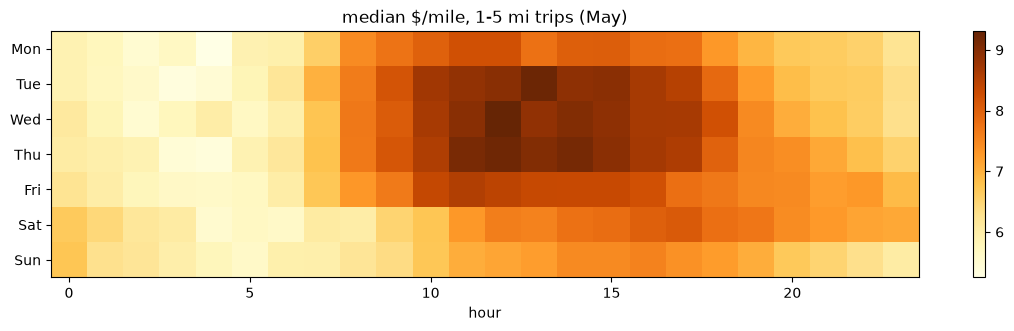

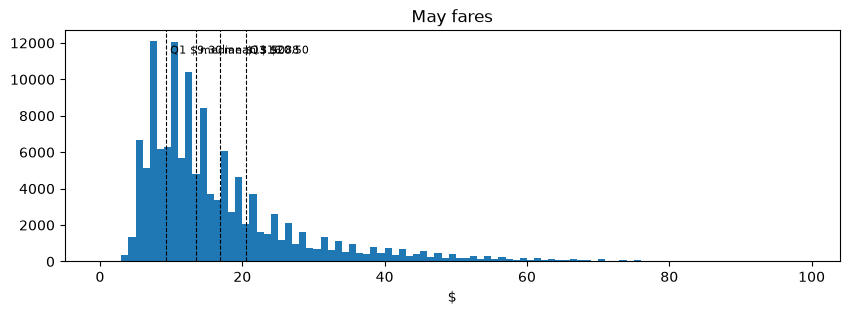

In [14]:
mid = f[(f.trip_distance > 1) & (f.trip_distance <= 5)]
grid = mid.pivot_table(index="dow", columns="hour", values="fare_per_mile", aggfunc="median").round(2)
grid_n = mid.pivot_table(index="dow", columns="hour", values="fare_per_mile", aggfunc="size")
fig, ax = plt.subplots(figsize=(14, 3.2)); im = ax.imshow(grid, aspect="auto", cmap="YlOrBr")
ax.set(yticks=range(7), yticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], xlabel="hour", title="median $/mile, 1-5 mi trips (May)"); plt.colorbar(im)
print("most expensive cell:", grid.stack().idxmax(), grid.stack().max(), "| cheapest:", grid.stack().idxmin(), grid.stack().min())
fare_hist = histogram(f[TARGET], np.arange(0, 100, 2))
fig, ax = plt.subplots(figsize=(10, 3)); ax.hist(f[TARGET], bins=np.arange(0, 100, 1))
for v, lab in [(summary.loc["fare_amount", "q1"], "Q1"), (summary.loc["fare_amount", "median"], "median"), (summary.loc["fare_amount", "mean"], "mean"), (summary.loc["fare_amount", "q3"], "Q3")]:
    ax.axvline(v, color="k", ls="--", lw=.8); ax.text(v, ax.get_ylim()[1] * .9, f" {lab} ${v:.2f}", fontsize=8)
ax.set(title="May fares", xlabel="$")

**Read it.** For 1–5 mile trips, the most expensive mile is **Wednesday around noon** (median \$9.31/mi) and the cheapest is **Monday around 4 am** (\$5.25/mi): 77% more for the same distance. Weekday midday and afternoon hours are consistently the dearest, and nights and early mornings the cheapest. The fare histogram shows the right skew: Q1 \$9.30 < median \$13.50 < mean \$16.88 < Q3 \$20.50.

In [15]:
def recs(t): return json.loads(t.reset_index().to_json(orient="records"))
save_results({
    "summary_may": recs(summary.rename_axis("measure")),
    "months": recs(month_tab.rename_axis("measure")),
    "quartiles": {by: {k: recs(v) for k, v in g.items()} for by, g in groups.items()},
    "rankings": {k: {side: recs(t) for side, t in v.items()} for k, v in rank.items()},
    "top_trips": recs(top_trips.reset_index(drop=True)), "cheapest_trips": recs(cheap_trips.reset_index(drop=True)),
    "n_minimum_fare": int((f[TARGET] == 3.0).sum()),
    "slow_share": float((f.speed_mph < 6).mean()), "slow_median_fpm": float(slow.fare_per_mile.median()), "median_fpm": float(f.fare_per_mile.median()),
    "raw_over_100": {"n": int(len(big)), "share": float(len(big) / len(rm)), "kept": int((train[TARGET] > 100).sum()), "by_kind": recs(raw_big)},
    "fpm_dow_hour": {"median": grid.values.tolist(), "n": grid_n.values.tolist()},
    "fare_hist": fare_hist,
}, "eda_summary.json")

PosixPath('/home/blevi/school-related/Fairfare/results/eda_summary.json')

## Summary
- **Straight-line routing:** k by straight-line length (1.17–1.79, fitted on May). June distance error 0.53 mi on average. The frozen model's June MAE becomes **\$3.26** (vs \$2.08 with odometer distances), and a re-calibrated per-band buffer restores 90% cross-fitted coverage at an average cushion of \$5.27. Validated on June only; July was not used.
- **Fares (May):** mean \$16.88, median \$13.50, Q1 \$9.30, Q3 \$20.50. Most expensive: airport runs and long cross-borough routes (JFK → North Brooklyn ≈ \$65). Most expensive per mile: short Midtown hops at under 5 mph (up to \$15.74/mi). Cheapest: short same-zone hops on the Upper East/West Side (≈ \$5–6), and per mile, fast highway trips from JFK (≈ \$3.90/mi).